# 03 · Explainability (SHAP)

The deployed model is explained end-to-end — feature engineering, classifier chain, soft vote and
calibration included — with **permutation SHAP** in log-odds space over the 55 schema features.
Every attribution therefore maps to exactly one clinical input the user can edit, and
`base value + Σ contributions = logit(predicted probability)` holds exactly.

Background: 30 real dev-set patients (interventional). All four targets are explained in one
multi-output pass, so chained targets add no cost.

In [1]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from vascora_ml import config, data, models

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
REPORTS = config.REPORTS_DIR
REPORTS.mkdir(exist_ok=True)
TARGETS = data.target_keys()
TARGET_LABELS = {t: data.load_registry()["targets"][t]["label"] for t in TARGETS}
FEATURE_LABELS = {f.key: f.label for f in data.features()}

In [2]:
import time

import shap

from vascora_ml.explain import explanation_records, global_importance, logit
from vascora_ml.train import prepare

bundle = joblib.load(config.ARTIFACTS_DIR / "vascora_model.joblib")
model, explainer = bundle["model"], bundle["explainer"]
ds = prepare()
t0 = time.perf_counter()
sv = explainer.explain(ds.Xb_test, permutations=6)
print(f"explained {len(ds.Xb_test)} test patients x {len(TARGETS)} targets in {time.perf_counter() - t0:.1f}s")

explained 61 test patients x 4 targets in 112.8s


In [3]:
probs = model.predict_proba(ds.Xb_test)
for t in TARGETS:
    recon = sv[t].base_values + sv[t].values.sum(axis=1)
    err = np.abs(recon - logit(probs[t])).max()
    print(f"{t}: max additivity error {err:.2e}")

CAD: max additivity error 4.44e-15
LAD: max additivity error 2.66e-15
LCX: max additivity error 2.22e-15
RCA: max additivity error 1.78e-15


## Global importance (mean |SHAP| on the test set)

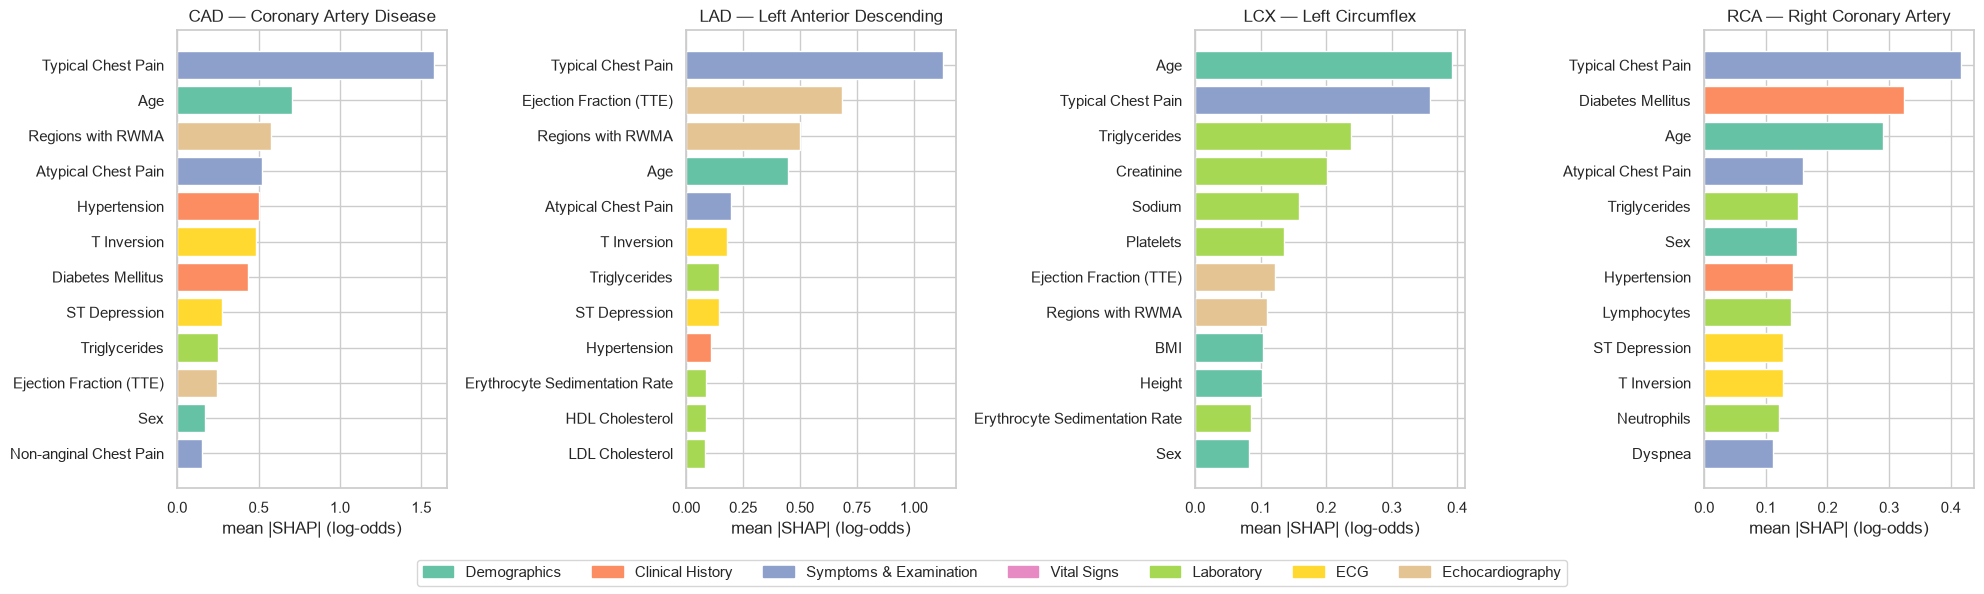

In [4]:
imp = {t: global_importance(sv[t]) for t in TARGETS}
fig, axes = plt.subplots(1, 4, figsize=(20, 6))
cat_colors = dict(zip(data.load_schema()["categories"], sns.color_palette("Set2", 7)))
for ax, t in zip(axes, TARGETS):
    d = imp[t].head(12).iloc[::-1]
    ax.barh(d.label, d.mean_abs_shap, color=[cat_colors[c] for c in d.category])
    ax.set_title(f"{t} — {TARGET_LABELS[t]}"); ax.set_xlabel("mean |SHAP| (log-odds)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cat_colors.values()]
fig.legend(handles, data.load_schema()["categories"].values(), loc="lower center", ncol=7)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.savefig(REPORTS / "shap_global.png", dpi=150); plt.show()

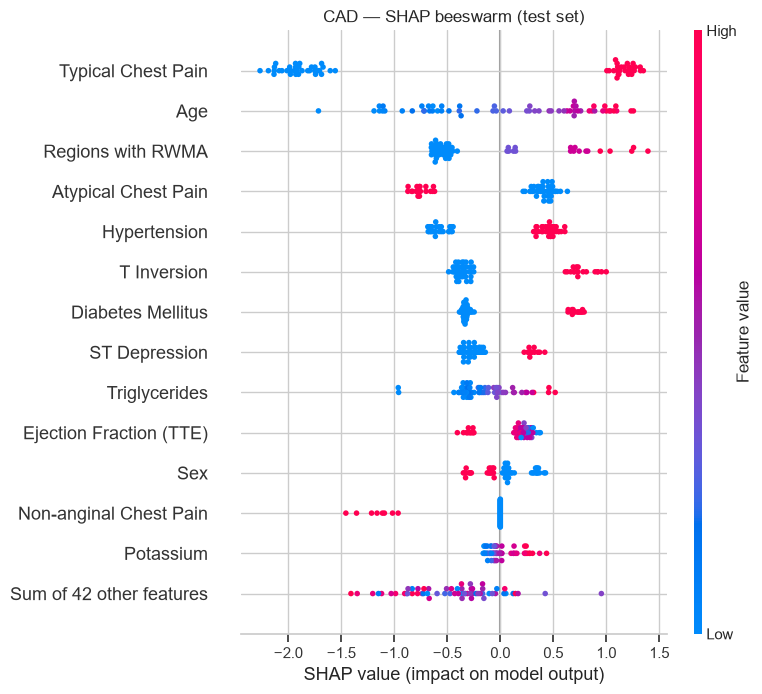

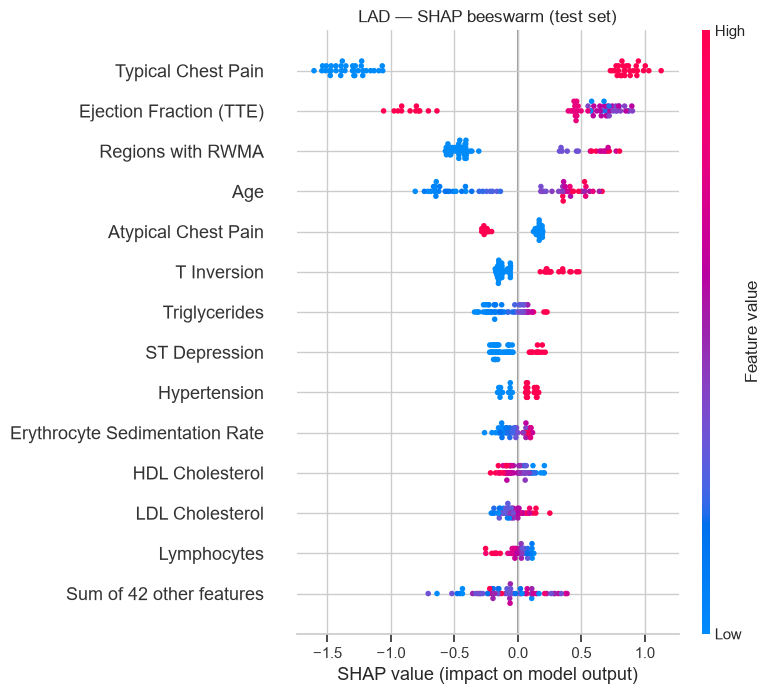

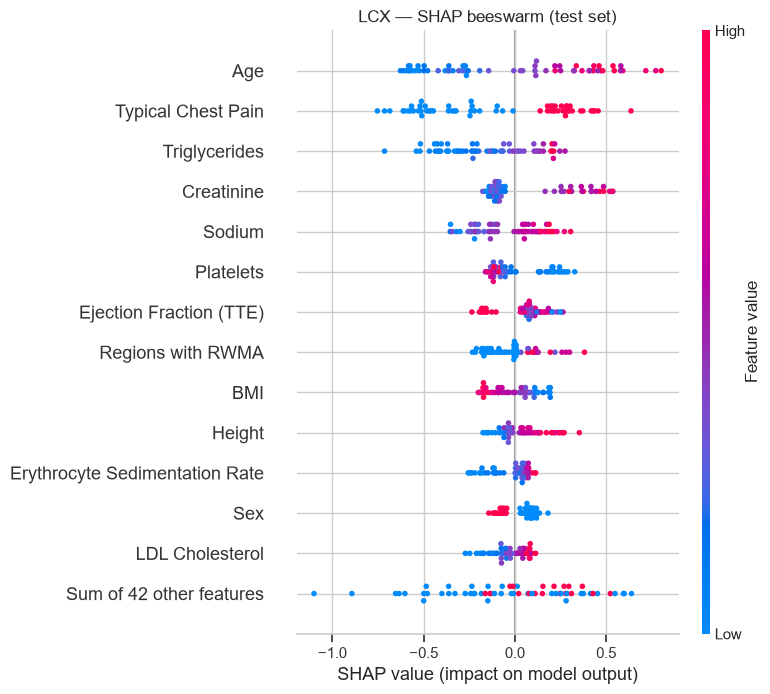

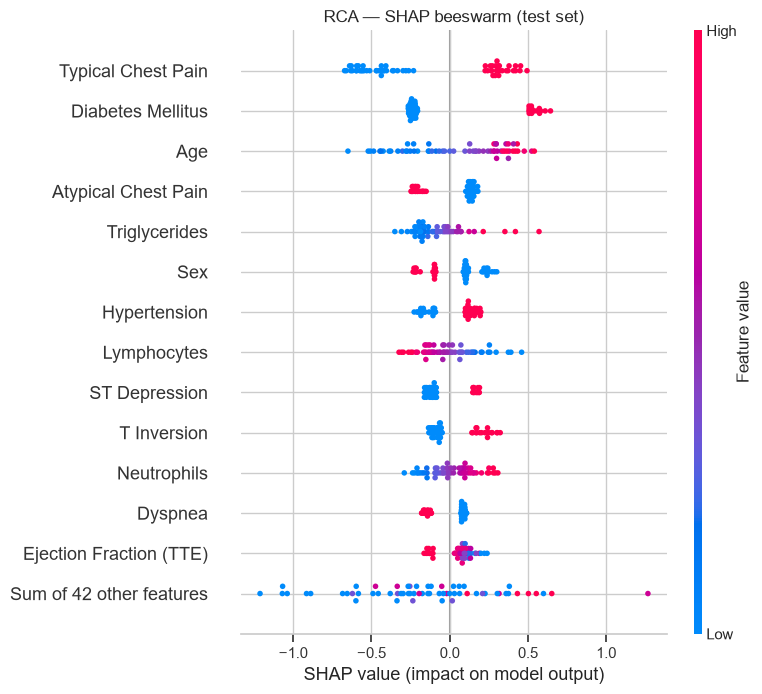

In [5]:
for t in TARGETS:
    e = sv[t]
    e.feature_names = [FEATURE_LABELS[k] for k in explainer.keys]
    plt.figure()
    shap.plots.beeswarm(e, max_display=14, show=False)
    plt.title(f"{t} — SHAP beeswarm (test set)")
    plt.tight_layout(); plt.savefig(REPORTS / f"shap_beeswarm_{t}.png", dpi=150, bbox_inches="tight")
    plt.show()
    e.feature_names = explainer.keys

## Physiological breakdown by category

Sum of absolute contributions per clinical category — the grouping shown in the dashboard.

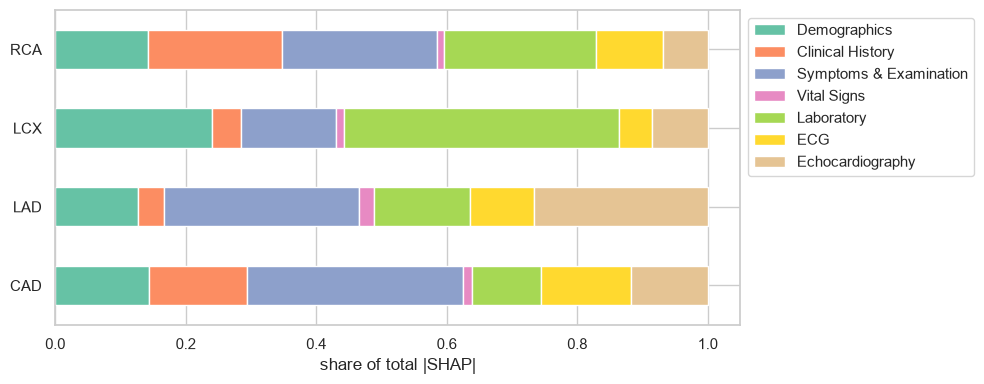

,CAD,LAD,LCX,RCA
category,,,,
Demographics,14.4%,12.7%,24.0%,14.2%
Clinical History,15.0%,3.9%,4.5%,20.5%
Symptoms & Examination,33.1%,29.9%,14.6%,23.8%
Vital Signs,1.4%,2.2%,1.1%,1.1%
Laboratory,10.6%,14.8%,42.2%,23.4%
ECG,13.8%,9.7%,5.1%,10.2%
Echocardiography,11.7%,26.7%,8.5%,6.9%


In [6]:
cats = data.load_schema()["categories"]
share = pd.DataFrame({t: imp[t].groupby("category").mean_abs_shap.sum() for t in TARGETS}).fillna(0)
share = (share / share.sum()).loc[list(cats)].rename(index=cats)
ax = share.T.plot.barh(stacked=True, figsize=(10, 4), color=list(cat_colors.values()))
ax.set_xlabel("share of total |SHAP|"); ax.legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.savefig(REPORTS / "shap_categories.png", dpi=150); plt.show()
share.style.format("{:.1%}")

## Local explanation: one high-risk test patient

patient row: 230 | true labels: {'CAD': 1, 'LAD': 1, 'LCX': 0, 'RCA': 0}
{'CAD': 1.0, 'LAD': 0.982, 'LCX': 0.769, 'RCA': 0.631}


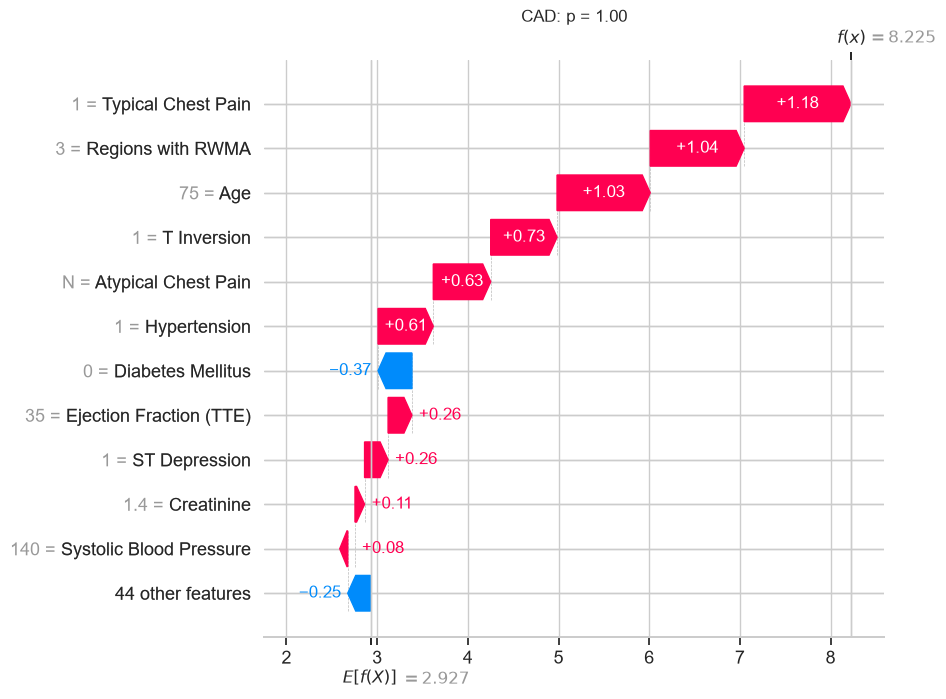

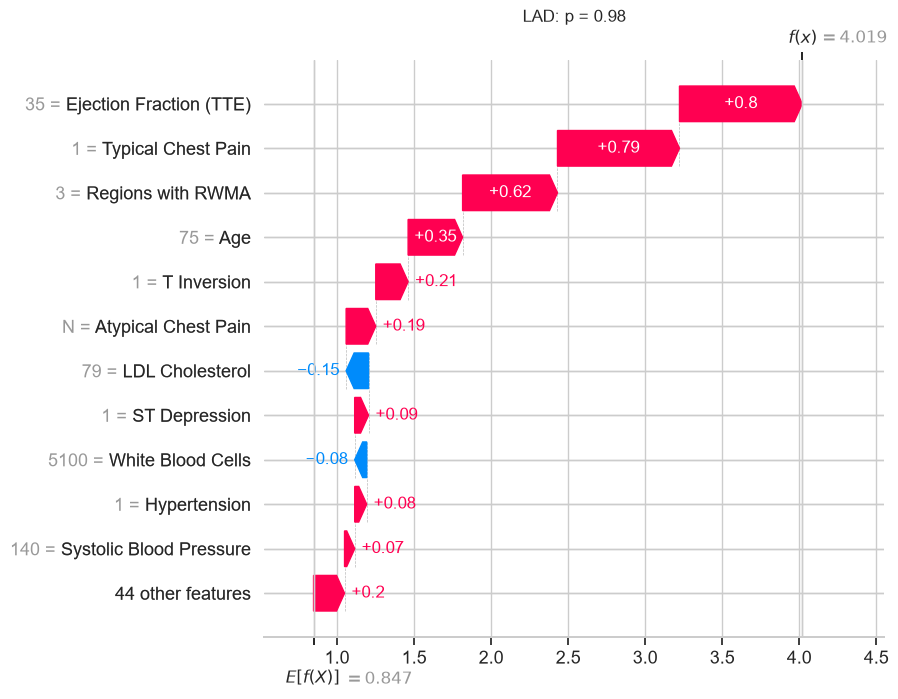

In [7]:
i = int(np.argmax(probs["CAD"] + probs["LAD"]))
patient = ds.X_test.iloc[i]
print("patient row:", ds.X_test.index[i], "| true labels:", ds.Y_test.iloc[i].to_dict())
print({t: round(float(probs[t][i]), 3) for t in TARGETS})
for t in ["CAD", "LAD"]:
    e = sv[t][i]
    e.feature_names = [FEATURE_LABELS[k] for k in explainer.keys]
    e.data = np.array([data.decode_value(k, v) for k, v in zip(explainer.keys, e.data)], dtype=object)
    plt.figure()
    shap.plots.waterfall(e, max_display=12, show=False)
    plt.title(f"{t}: p = {probs[t][i]:.2f}")
    plt.savefig(REPORTS / f"shap_waterfall_{t}.png", dpi=150, bbox_inches="tight"); plt.show()

In [8]:
rec = explanation_records(sv["LAD"][i : i + 1], ds.Xb_test.iloc[i : i + 1])[0]
pd.DataFrame(rec["contributions"]).head(10)

,key,label,category,value,contribution
0,ef_tte,Ejection Fraction (TTE),echo,35.0,0.797
1,typical_chest_pain,Typical Chest Pain,symptoms,1,0.792
2,region_rwma,Regions with RWMA,echo,3,0.616
3,age,Age,demographic,75.0,0.354
4,t_inversion,T Inversion,ecg,1,0.210
5,atypical,Atypical Chest Pain,symptoms,N,0.192
6,ldl,LDL Cholesterol,labs,79.0,-0.146
7,st_depression,ST Depression,ecg,1,0.090
8,wbc,White Blood Cells,labs,5100.0,-0.078
9,htn,Hypertension,history,1,0.078


## Serving latency (no GPU)

The API explains one patient for all four targets per request with the default
(2-permutation) setting.

In [9]:
x = ds.Xb_test.iloc[[0]]
for name, fn in [("predict", lambda: model.predict_proba(x)),
                 ("predict + 90% interval", lambda: model.predict_interval(x)),
                 ("SHAP, all targets", lambda: explainer.explain(x))]:
    fn()
    t0 = time.perf_counter()
    for _ in range(3):
        fn()
    print(f"{name:24s} {(time.perf_counter() - t0) / 3 * 1000:7.0f} ms")

predict                       40 ms


predict + 90% interval       421 ms


SHAP, all targets            503 ms
